In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt
import pytensor.tensor as pt
from pathlib import Path
from scipy.stats import gaussian_kde

g++ not available, if using conda: `conda install gxx`


In [2]:
path = Path("..").joinpath(
    "data_observation"
)

flat_df = pd.read_csv(path.joinpath("TT_Res_Data_R3.csv"))

# Sort the DataFrame by travelTimeMeta_ID and ztop_TT
flat_df = flat_df.sort_values(by=['travelTimeMeta_ID', 'ztop_TT'])

tt_ids = flat_df['travelTimeMeta_ID']
Vsi_raw = flat_df['Vsi']
Qtn_raw = flat_df['Qtn_TT']
Ic_raw = flat_df['Ic_TT']
sigmavp_raw = flat_df['sigmavp_TT']
ztop_raw = flat_df['ztop_TT']
zbot_raw = flat_df['zbot_TT']
group_text_raw = flat_df['group']
group_ids_raw = flat_df['group_id']

valid_indices = (sigmavp_raw > 0) & (Qtn_raw > 0) & (Vsi_raw > 50) & (Vsi_raw < 1000) & (Ic_raw < 4.0)

tt_ids = np.asarray(tt_ids[valid_indices]) # equevalent to SJB's profile_id_vs
Qtn = np.asarray(Qtn_raw[valid_indices])
Vsi = np.asarray(Vsi_raw[valid_indices])
Ic = np.asarray(Ic_raw[valid_indices])
sigmavp = np.asarray(sigmavp_raw[valid_indices])
ztop = np.asarray(ztop_raw[valid_indices])
zbot = np.asarray(zbot_raw[valid_indices])
group_text = np.asarray(group_text_raw[valid_indices])
group_ids_TT = np.asarray(group_ids_raw[valid_indices])
unique_tt_ids = np.unique(tt_ids)
tt_index = np.searchsorted(unique_tt_ids, tt_ids) #equavelent to SJB's profile_index_vs
unique_group_id_tt = np.unique(group_ids_TT)
group_index_tt = np.searchsorted(unique_group_id_tt, group_ids_TT)

In [7]:
# create a unique layer ID for each layer
layer_ids = np.arange(len(tt_ids)) # Equevalent to SJB's tt_ids

In [ ]:
flat_comp_df = pd.read_csv(path.joinpath("CPT_Res_Data_R3.csv"))

tt_ids_CPT = np.asarray(flat_comp_df['travelTimeMeta_ID'])
CPT_depth = np.asarray(flat_comp_df['CPT_depth'])
sigmavp_CPT = np.asarray(flat_comp_df['sigmavp_CPT'])
Ic_CPT = np.asarray(flat_comp_df['Ic_CPT'])
Qtn_CPT = np.asarray(flat_comp_df['Qtn_CPT'])
group_ids_CPT = np.asarray(flat_comp_df['group_id'])

In [9]:
# Output array
lay_id_assign = np.full(len(CPT_depth), -1)

# Vectorized matching
for i in range(len(layer_ids)):

    mask = (
        (tt_ids_CPT == tt_ids[i]) &
        (CPT_depth >= ztop[i]) &
        (CPT_depth < zbot[i])
    )

    lay_id_assign[mask] = layer_ids[i]

In [10]:
index = (lay_id_assign > -0.1) & (Qtn_CPT > 0) & (sigmavp_CPT > 0)
tt_ids_CPT_valid = np.asarray(tt_ids_CPT[index])
CPT_depth_valid = np.asarray(CPT_depth[index])
sigmavp_CPT_valid = np.asarray(sigmavp_CPT[index])
Ic_CPT_valid = np.asarray(Ic_CPT[index])
Qtn_CPT_valid = np.asarray(Qtn_CPT[index])
lay_id_assign_valid = np.asarray(lay_id_assign[index]) # Equevalent to SJB's tt_ids_CPT
group_ids_CPT_valid = np.asarray(group_ids_CPT[index])

tt_ids_CPT_unique = np.unique(tt_ids_CPT_valid)
tt_index_CPT = np.searchsorted(tt_ids_CPT_unique, tt_ids_CPT_valid)
group_id_CPT_unique = np.unique(group_ids_CPT_valid)
group_index_CPT = np.searchsorted(group_id_CPT_unique, group_ids_CPT_valid)

In [17]:
layer_ids

array([    0,     1,     2, ..., 12130, 12131, 12132], shape=(12133,))

In [18]:
len(lay_id_assign_valid)

432534

In [11]:
indices = np.searchsorted(lay_id_assign_valid, layer_ids)
dz = (zbot - ztop) / np.diff(np.concatenate((indices, [len(CPT_depth_valid)])))
tt = (zbot - ztop) / Vsi # it's actually delta_tt
ln_tt = np.log (tt)
tt_profile = np.bincount(tt_index, weights = tt)
ln_tt_profile = np.log (tt_profile)

In [12]:
# create filter for each group
unique_groups = np.unique(group_ids_CPT_valid)
group_filter = {group: (group_ids_CPT_valid == group) for group in unique_groups}

Geology_1 = group_filter[1]
Geology_2 = group_filter[2]
Geology_3 = group_filter[3]
Geology_4 = group_filter[4]
Geology_5 = group_filter[5]
Geology_6 = group_filter[6]
Geology_7 = group_filter[7]
Geology_8 = group_filter[8]
Geology_9 = group_filter[9]
Geology_10 = group_filter[10]
Geology_11 = group_filter[11]

In [13]:
unique_groups

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [14]:
# Inputs
Y = Vsi
X1 = Qtn_CPT_valid
X2 = sigmavp_CPT_valid
X3 = Ic_CPT_valid
lnY = np.log(Y)
lnX2 = np.log(X2)

p_id = len(unique_tt_ids)
l_id = len(layer_ids)
N_tt = np.bincount(lay_id_assign_valid)
N_geology = len(unique_groups)

In [15]:
def tt_hat_pt(b, a_cpt):
    # Predicted travel time for each VS interval. a_cpt is a scalar or a per-CPT-point intercept.
    # Kc and fIc use the same sigmoid form as the student's code, written in terms of slope and center:
    # b = [b1, Kc slope, Kc center, fIc slope, fIc center]. The student's exp(-b2*Ic + b3) has center b3/b2,
    # which makes b2 and b3 strongly correlated and slows NUTS; sampling slope and center directly avoids that.
    Kc = 1.0 + 5.0 / (1.0 + pt.exp(-b[1] * (Ic_CPT_valid - b[2])))
    fIc = 0.1 + 0.4 / (1.0 + pt.exp(-b[3] * (Ic_CPT_valid - b[4])))
    ln_S_hat = -(b[0] * pt.log(Qtn_CPT_valid * Kc) + fIc * pt.log(sigmavp_CPT_valid) + a_cpt)
    return dz * pt.bincount(lay_id_assign_valid, weights=pt.exp(ln_S_hat), minlength=len(tt))

def marginal_logp(res, phi_p2p, d):
    # Log-likelihood of the interval residuals with the profile terms integrated out. Within profile p,
    # res_p ~ MVN(0, phi_p2p^2 * J + diag(d)), where d is the variance of each interval's residual after
    # removing the profile term. Sherman-Morrison gives, with s1 = sum(1/d):
    #   log|V| = sum(log d) + log(1 + phi_p2p^2 * s1)
    #   res' V^-1 res = sum(res^2/d) - phi_p2p^2 * sum(res/d)^2 / (1 + phi_p2p^2 * s1)
    s1 = pt.bincount(tt_index, weights=1.0 / d, minlength=p_id)
    sr = pt.bincount(tt_index, weights=res / d, minlength=p_id)
    srr = pt.bincount(tt_index, weights=res**2 / d, minlength=p_id)
    log_det = pt.bincount(tt_index, weights=pt.log(d), minlength=p_id) + pt.log1p(phi_p2p**2 * s1)
    quad = srr - phi_p2p**2 * sr**2 / (1.0 + phi_p2p**2 * s1)
    return -0.5 * (len(tt) * np.log(2.0 * np.pi) + pt.sum(log_det + quad))

In [16]:
# Create baseline model with no random effects
with pm.Model() as model1:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=0, sigma=10)
    sigma = pm.HalfNormal('sigma', sigma=10)
    tt_hat = tt_hat_pt(b, a)
    pm.Deterministic("tt_hat", tt_hat)

    likelihood = pm.Normal(
        'likelihood', mu = pt.log(tt_hat), sigma = sigma, observed = ln_tt
    )

    map_estimate1 = pm.find_MAP(start = {"b": [0.25, 14.0, 2.1, 2.5, 2.47], "a": 4, "sigma": 0.25})

Output()

In [17]:
map_estimate1

{'b': array([0.26690705, 9.54213088, 2.2110304 , 1.49093946, 2.66980946]),
 'a': array(4.13431022),
 'sigma_log__': array(-1.35052917),
 'sigma': array(0.25910311),
 'tt_hat': array([0.00975376, 0.00772974, 0.00652951, ..., 0.0045604 , 0.00423157,
        0.00456165], shape=(12133,))}

In [18]:
# Create model with geology-specific intercept, no random effects
coords = {'geology': np.arange(N_geology)}
with pm.Model(coords = coords) as model2:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=4, sigma=10, dims='geology')
    sigma = pm.HalfNormal('sigma', sigma=1)
    tt_hat = tt_hat_pt(b, a[group_index_CPT])
    pm.Deterministic("tt_hat", tt_hat)

    likelihood = pm.Normal(
        'likelihood', mu = pt.log(tt_hat), sigma = sigma, observed = ln_tt
    )

    map_estimate2 = pm.find_MAP(start={'b': map_estimate1['b'], 'a': np.full(N_geology, map_estimate1['a']),
                                       'sigma': map_estimate1['sigma']})

Output()

In [19]:
map_estimate2

{'b': array([0.23008539, 7.49465619, 2.25847303, 0.82351835, 3.18415878]),
 'a': array([4.40310394, 4.24336953, 4.18534378, 4.17373011, 4.22902676,
        4.28942356, 4.31878831, 4.37918699, 4.35087666, 4.45570482,
        4.41512372]),
 'sigma_log__': array(-1.39640919),
 'sigma': array(0.24748404),
 'tt_hat': array([0.00893327, 0.0072191 , 0.00619229, ..., 0.00462282, 0.00430155,
        0.0046174 ], shape=(12133,))}

In [20]:
# Mixed-effects model where we separate the uncertainty into phi_p2p and phi_wp terms, but keep a constant.
# The profile terms eta_p2p are integrated out analytically in marginal_logp rather than estimated as latent
# variables, because find_MAP over latent random effects and their standard deviation jointly tends to
# shrink the standard deviation toward zero.

with pm.Model() as model3:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=4, sigma=10)
    phi_p2p = pm.HalfNormal('phi_p2p', sigma=1)
    phi_wp = pm.HalfNormal('phi_wp', sigma=1)

    res = ln_tt - pt.log(tt_hat_pt(b, a))
    pm.Potential('likelihood', marginal_logp(res, phi_p2p, phi_wp**2 * pt.ones(len(tt))))

    map_estimate3 = pm.find_MAP(start={'b': map_estimate1['b'], 'a': map_estimate1['a'],
                                       'phi_p2p': 0.15, 'phi_wp': 0.2})

Output()

In [21]:
map_estimate3

{'b': array([0.23481467, 5.70231097, 2.24572912, 1.28138188, 2.59264474]),
 'a': array(4.28336005),
 'phi_p2p_log__': array(-1.93402066),
 'phi_wp_log__': array(-1.51177609),
 'phi_p2p': array(0.14456578),
 'phi_wp': array(0.22051797)}

In [23]:
with pm.Model() as model3p1:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=4, sigma=10)
    phi_p2p = pm.HalfNormal('phi_p2p', sigma=1)
    phi_l2l = pm.HalfNormal('phi_l2l', sigma=1)
    phi_wl = pm.HalfNormal('phi_wl', sigma=1)

    res = ln_tt - pt.log(tt_hat_pt(b, a))
    d = phi_l2l**2 + phi_wl**2 / N_tt
    pm.Potential('likelihood', marginal_logp(res, phi_p2p, d))
    map_estimate3p1 = pm.find_MAP(start={'b': map_estimate3['b'], 'a': map_estimate3['a'],
                                       'phi_p2p': map_estimate3['phi_p2p'], 'phi_l2l': map_estimate3['phi_wp'], 'phi_wl': 0.4 })

Output()

In [24]:
map_estimate3p1

{'b': array([0.23602002, 5.95381088, 2.23490333, 1.49929127, 2.55738856]),
 'a': array(4.27704752),
 'phi_p2p_log__': array(-1.92947975),
 'phi_l2l_log__': array(-1.62590718),
 'phi_wl_log__': array(-0.77193443),
 'phi_p2p': array(0.14522373),
 'phi_l2l': array(0.19673312),
 'phi_wl': array(0.46211827)}

In [25]:
import time

start_time = time.time()
with model3p1:
    traces5 = pm.sample(
        initvals={k: map_estimate3p1[k] for k in ['b', 'a', 'phi_p2p', 'phi_l2l', 'phi_wl']},
        init='adapt_diag',
        random_seed=2026,
    )
print(f"Sampling took {(time.time() - start_time) / 60:.1f} minutes")

Initializing NUTS using adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, phi_p2p, phi_l2l, phi_wl]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 840 seconds.


Sampling took 14.0 minutes


In [26]:
import arviz as az
                               
az.summary(traces5)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
b[0],0.2359,0.0039,0.23,0.24,2814,2386,1.00,7.4e-05,6.7e-05
b[1],5.98,0.35,5.4,6.6,4041,3203,1.00,0.0056,0.0052
b[2],2.2347,0.0207,2.2,2.3,3936,2862,1.00,0.00033,0.00033
b[3],1.499,0.111,1.3,1.7,4154,3022,1.00,0.0017,0.0016
b[4],2.5586,0.031,2.5,2.6,4830,3150,1.00,0.00045,0.00053
a,4.2776,0.0183,4.2,4.3,2836,2482,1.00,0.00034,0.0003
phi_p2p,0.1455,0.0039,0.14,0.15,4717,3159,1.00,5.6e-05,6.3e-05
phi_l2l,0.19674,0.00252,0.19,0.2,3149,3081,1.00,4.5e-05,3.5e-05
phi_wl,0.4623,0.0238,0.42,0.5,3063,2779,1.00,0.00043,0.00035


In [ ]:
# Now move on to model where a depends on geology

coords = {"geology": np.arange(N_geology)}
with pm.Model(coords=coords) as model4:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=0, sigma=10, dims="geology")
    phi_p2p = pm.HalfNormal('phi_p2p', sigma=1)
    phi_wp = pm.HalfNormal('phi_wp', sigma=1)

    res = ln_tt - pt.log(tt_hat_pt(b, a[group_index_CPT]))
    pm.Potential('likelihood', marginal_logp(res, phi_p2p, phi_wp**2 * pt.ones(len(tt))))

    map_estimate4 = pm.find_MAP(start={'b': map_estimate3['b'], 'a': np.full(N_geology, map_estimate3['a']),
                                       'phi_p2p': map_estimate3['phi_p2p'], 'phi_wp': map_estimate3['phi_wp']})

In [21]:
map_estimate4

{'b': array([0.22289505, 5.34251667, 2.26147779, 1.07326445, 2.70019984]),
 'a': array([4.41246562, 4.2627721 , 4.20479887, 4.20321265, 4.24357194,
        4.32251358, 4.35808294, 4.42081898, 4.39274707, 4.52097828,
        4.43084989]),
 'phi_p2p_log__': array(-2.14404598),
 'phi_wp_log__': array(-1.51294108),
 'phi_p2p': array(0.11717978),
 'phi_wp': array(0.22026122)}

In [22]:
coords = {"geology": np.arange(N_geology)}
with pm.Model(coords=coords) as model5:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=0, sigma=10, dims="geology")
    phi_p2p = pm.HalfNormal('phi_p2p', sigma=1)
    phi_l2l = pm.HalfNormal('phi_l2l', sigma=1)
    phi_wl = pm.HalfNormal('phi_wl', sigma=1)

    res = ln_tt - pt.log(tt_hat_pt(b, a[group_index_CPT]))
    d = phi_l2l**2 + phi_wl**2 / N_tt
    pm.Potential('likelihood', marginal_logp(res, phi_p2p, d))
    map_estimate5 = pm.find_MAP(start={'b': map_estimate4['b'], 'a': map_estimate4['a'],
                                       'phi_p2p': map_estimate4['phi_p2p'],
                                       'phi_l2l': map_estimate4['phi_wp'], 'phi_wl': 0.3})

In [23]:
map_estimate5

{'b': array([0.22395591, 5.49887396, 2.2481971 , 1.28192183, 2.65138705]),
 'a': array([4.40399816, 4.25777384, 4.19644728, 4.1973405 , 4.24067893,
        4.31798246, 4.35177866, 4.41351564, 4.38552831, 4.51719323,
        4.42329023]),
 'phi_p2p_log__': array(-2.13255104),
 'phi_l2l_log__': array(-1.62445439),
 'phi_wl_log__': array(-0.78522598),
 'phi_p2p': array(0.11853452),
 'phi_l2l': array(0.19701914),
 'phi_wl': array(0.45601664)}

In [24]:
import time

start_time = time.time()
with model5:
    traces5 = pm.sample(
        initvals={k: map_estimate5[k] for k in ['b', 'a', 'phi_p2p', 'phi_l2l', 'phi_wl']},
        init='adapt_diag',
        random_seed=2026,
    )
print(f"Sampling took {(time.time() - start_time) / 60:.1f} minutes")

Auto-assigning NUTS sampler...
Initializing NUTS using adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, phi_p2p, phi_l2l, phi_wl]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 5231 seconds.


Sampling took 87.6 minutes


In [25]:
import arviz as az
                               
az.summary(traces5)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
b[0],0.224,0.004,0.215,0.231,0.000,0.000,797.0,1380.0,1.01
b[1],5.510,0.354,4.879,6.206,0.006,0.005,3141.0,2612.0,1.00
b[2],2.248,0.023,2.208,2.292,0.000,0.000,3868.0,3364.0,1.00
b[3],1.283,0.104,1.087,1.471,0.002,0.001,3203.0,2967.0,1.00
b[4],2.652,0.039,2.575,2.726,0.001,0.000,3680.0,2882.0,1.00
a[0],4.405,0.021,4.364,4.444,0.001,0.000,984.0,1753.0,1.00
a[1],4.259,0.019,4.223,4.296,0.001,0.000,896.0,1638.0,1.00
a[2],4.198,0.023,4.153,4.240,0.001,0.000,1340.0,2084.0,1.00
a[3],4.199,0.030,4.144,4.256,0.001,0.001,1683.0,2503.0,1.00
a[4],4.242,0.025,4.199,4.292,0.001,0.000,1258.0,2107.0,1.00


In [1]:
import pickle

with open("trace_geo.pkl", "wb") as f:
    pickle.dump(traces5, f)

NameError: name 'traces5' is not defined

In [1]:
import pickle
import xarray as xr

# trace_geo.pkl was saved with ArviZ < 1.0 (arviz.data.InferenceData), which ArviZ 1.x removed.
# Unpickle the old object's groups and rebuild them as the DataTree that ArviZ 1.x uses.
class _OldInferenceData:
    def __setstate__(self, state):
        self.__dict__.update(state)

class _CompatUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module.startswith("arviz.data"):
            return _OldInferenceData
        return super().find_class(module, name)

with open("trace_geo.pkl", "rb") as f:
    _old = _CompatUnpickler(f).load()
traces5 = xr.DataTree.from_dict({g: getattr(_old, g) for g in _old._groups})

In [3]:
phi_p2p = traces5.posterior["phi_p2p"].mean(dim=("chain", "draw"))
phi_l2l = traces5.posterior["phi_l2l"].mean(dim=("chain", "draw"))
phi_wl = traces5.posterior["phi_wl"].mean(dim=("chain", "draw"))

In [7]:
sig = np.sqrt(phi_p2p ** 2 + phi_l2l ** 2 + phi_wl **2)
print (sig)

<xarray.DataArray ()> Size: 8B
array(0.51125106)


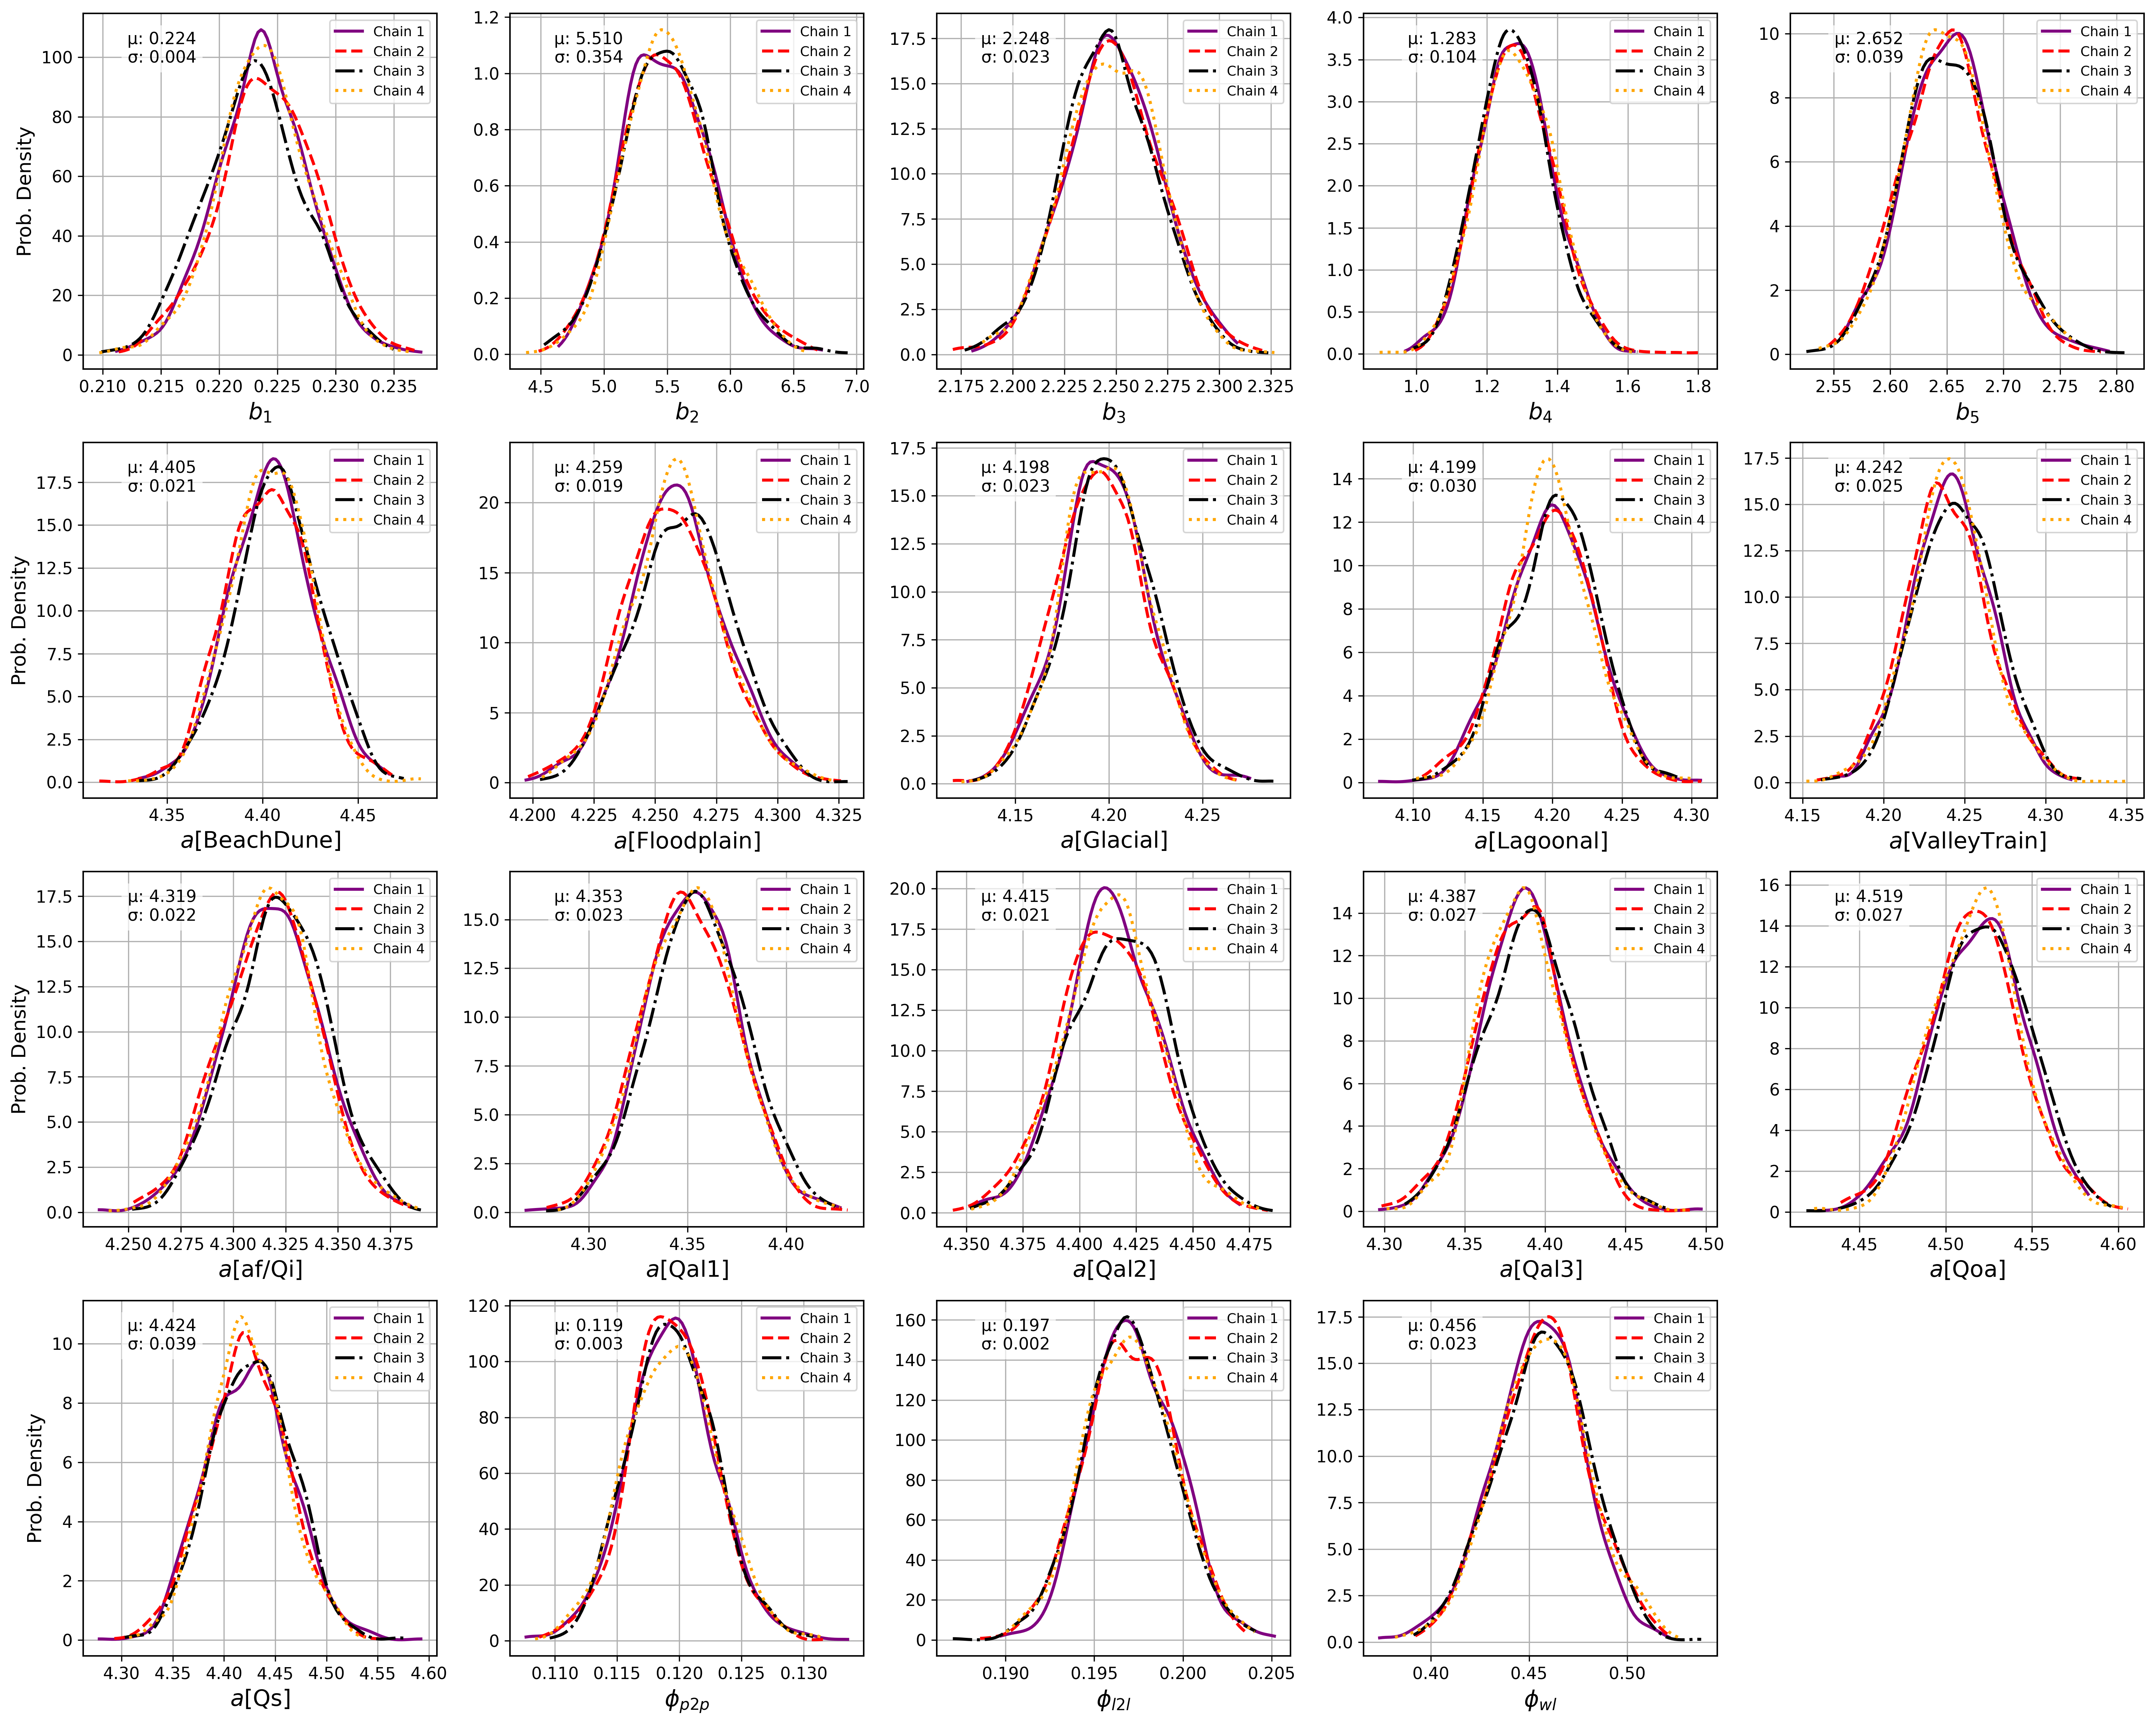

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Uses traces5 from the trace_geo.pkl loading cell above
n_a = traces5.posterior["a"].shape[2]  # 11
n_b = traces5.posterior["b"].shape[2]  # 5

geo_name = ['Beach Dune', 'Floodplain', 'Glacial', 'Lagoonal', 'ValleyTrain', 'af/Qi', 'Qal1', 'Qal2', 'Qal3', 'Qoa', 'Qs']

param_entries = []
for k in range(n_b):
    param_entries.append((f"$b_{k+1}$", traces5.posterior["b"].values[:, :, k]))
for k in range(n_a):
    param_entries.append((f"$a[{{\mathrm{{{geo_name[k]}}}}}]$", traces5.posterior["a"].values[:, :, k]))
for p, lbl in [("phi_p2p", r"$\phi_{p2p}$"), ("phi_l2l", r"$\phi_{l2l}$"), ("phi_wl", r"$\phi_{wl}$")]:
    param_entries.append((lbl, traces5.posterior[p].values))

n_params = len(param_entries)  # 19
ncols = 5
nrows = int(np.ceil(n_params / ncols))  # 4

linestyle = ['solid', 'dashed', 'dashdot', 'dotted']
color     = ['purple', 'red', 'black', 'orange']
label     = ['Chain 1', 'Chain 2', 'Chain 3', 'Chain 4']

fig, ax = plt.subplots(nrows, ncols, figsize=(20, 16), dpi=300)
ax_flat = ax.flat

for j, (lbl, data) in enumerate(param_entries):
    a = ax_flat[j]
    n_chains = data.shape[0]
    for i in range(n_chains):
        samples = data[i].flatten()
        kde = gaussian_kde(samples)
        x = np.linspace(samples.min(), samples.max(), 100)
        a.plot(x, kde(x), color=color[i], linewidth=2,
               linestyle=linestyle[i], label=label[i])

    mu = data.mean()
    sigma = data.std()
    a.text(0.32, 0.95, f"μ: {mu:.3f}\nσ: {sigma:.3f}",
           transform=a.transAxes, fontsize=11, ha='right', va='top',
           bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
    a.set_xlabel(lbl, fontsize=15)
    a.legend(fontsize=9, loc='upper right')
    a.grid()
    for spine in a.spines.values():
        spine.set_linewidth(1)
    a.tick_params(axis='both', labelsize=11)

# Hide unused axes
for j in range(n_params, nrows * ncols):
    ax_flat[j].set_visible(False)

# Y-axis labels on leftmost column
for row in range(nrows):
    ax[row, 0].set_ylabel('Prob. Density', fontsize=13)

plt.tight_layout()
plt.savefig('Posteriors_all.jpg', dpi=300, bbox_inches='tight')
plt.show()

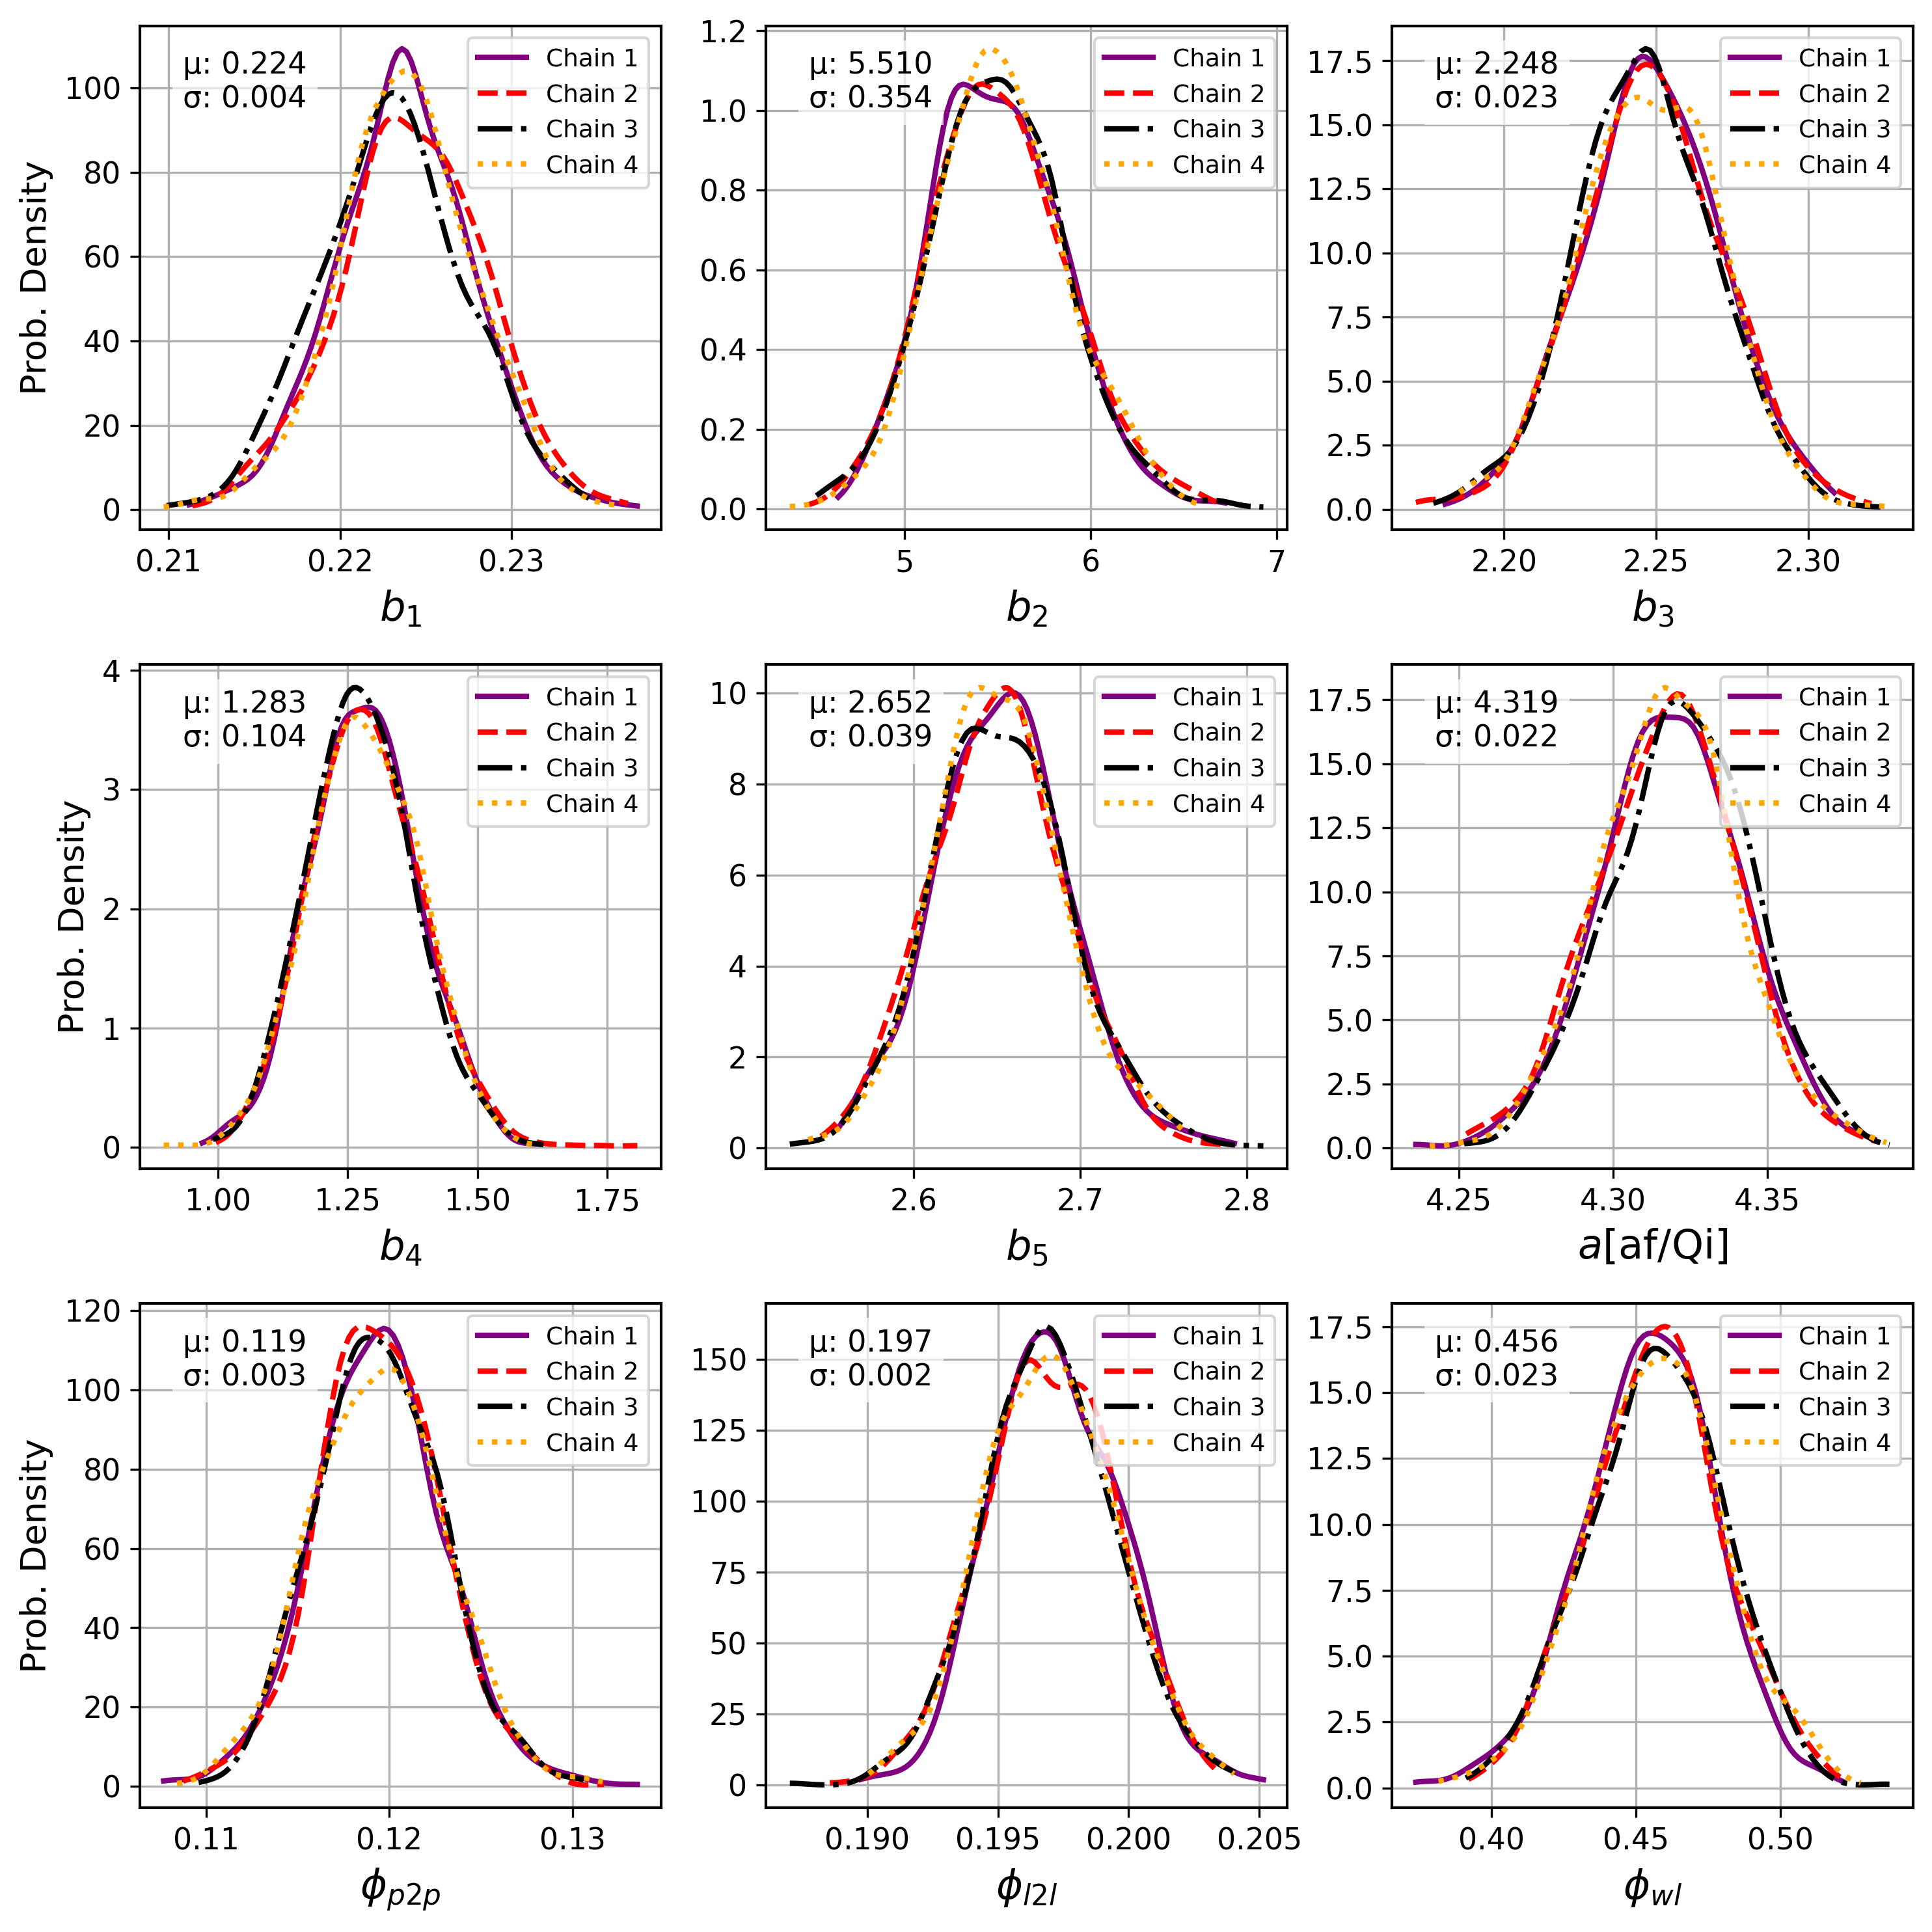

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# 3x3 subset: b1-b5, a[af/Qi], phi_p2p, phi_l2l, phi_wl
geo_name = ['Beach Dune', 'Floodplain', 'Glacial', 'Lagoonal', 'ValleyTrain', 'af/Qi', 'Qal1', 'Qal2', 'Qal3', 'Qoa', 'Qs']
k_afqi = geo_name.index('af/Qi')

param_entries = []
for k in range(5):
    param_entries.append((f"$b_{k+1}$", traces5.posterior["b"].values[:, :, k]))
param_entries.append((r"$a[\mathrm{af/Qi}]$", traces5.posterior["a"].values[:, :, k_afqi]))
for p, lbl in [("phi_p2p", r"$\phi_{p2p}$"), ("phi_l2l", r"$\phi_{l2l}$"), ("phi_wl", r"$\phi_{wl}$")]:
    param_entries.append((lbl, traces5.posterior[p].values))

nrows, ncols = 3, 3

linestyle = ['solid', 'dashed', 'dashdot', 'dotted']
color     = ['purple', 'red', 'black', 'orange']
label     = ['Chain 1', 'Chain 2', 'Chain 3', 'Chain 4']

fig, ax = plt.subplots(nrows, ncols, figsize=(10, 10), dpi=300)
ax_flat = ax.flat

for j, (lbl, data) in enumerate(param_entries):
    a = ax_flat[j]
    n_chains = data.shape[0]
    for i in range(n_chains):
        samples = data[i].flatten()
        kde = gaussian_kde(samples)
        x = np.linspace(samples.min(), samples.max(), 100)
        a.plot(x, kde(x), color=color[i], linewidth=2,
               linestyle=linestyle[i], label=label[i])

    mu = data.mean()
    sigma = data.std()
    a.text(0.32, 0.95, f"μ: {mu:.3f}\nσ: {sigma:.3f}",
           transform=a.transAxes, fontsize=11, ha='right', va='top',
           bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
    a.set_xlabel(lbl, fontsize=15)
    a.legend(fontsize=9, loc='upper right')
    a.grid()
    for spine in a.spines.values():
        spine.set_linewidth(1)
    a.tick_params(axis='both', labelsize=11)

# Y-axis labels on leftmost column
for row in range(nrows):
    ax[row, 0].set_ylabel('Prob. Density', fontsize=13)

plt.tight_layout()
plt.savefig('Posteriors_selected.jpg', dpi=300, bbox_inches='tight')
plt.show()

In [29]:
import pytensor

# Random effects for model5. The likelihood integrates eta_p2p out, so the effects are recovered here from their
# conditional distribution given each posterior draw, then combined over draws. Given the parameters,
# res_i = eta_p2p[p] + eta_l2l[i] + mean(eta_wl in layer i), with variances phi_p2p^2, phi_l2l^2, phi_wl^2 / N_tt[i]:
#   eta_p2p[p] = phi_p2p^2 * sum(res/d) / (1 + phi_p2p^2 * sum(1/d))
#   eta_l2l[i] = phi_l2l^2 / d[i] * (res[i] - eta_p2p[p])
#   eta_wl[i]  = phi_wl^2 / N_tt[i] / d[i] * (res[i] - eta_p2p[p])
# The three add up to res exactly. The travel times only constrain the layer average of eta_wl, so every
# CPT point in a layer gets the same eta_wl. Residuals are in ln(tt) space; ln(Vs) residuals are the negatives.
b_in, a_in = pt.dvector('b'), pt.dvector('a')
tt_hat_fn = pytensor.function([b_in, a_in], tt_hat_pt(b_in, a_in[group_index_CPT]))

def random_effects(b, a, phi_p2p, phi_l2l, phi_wl):
    # Returns the conditional means and variances of eta_p2p (per profile), eta_l2l and eta_wl (per layer)
    res = ln_tt - np.log(tt_hat_fn(b, a))
    v_l2l, v_wl = phi_l2l**2, phi_wl**2 / N_tt
    d = v_l2l + v_wl
    s1 = np.bincount(tt_index, weights=1.0 / d, minlength=p_id)
    sr = np.bincount(tt_index, weights=res / d, minlength=p_id)
    eta_p2p = phi_p2p**2 * sr / (1.0 + phi_p2p**2 * s1)
    r = res - eta_p2p[tt_index]
    Vinv_ii = 1.0 / d - phi_p2p**2 / (d**2 * (1.0 + phi_p2p**2 * s1[tt_index]))
    means = (eta_p2p, v_l2l / d * r, v_wl / d * r)
    variances = (phi_p2p**2 / (1.0 + phi_p2p**2 * s1), v_l2l - v_l2l**2 * Vinv_ii, v_wl - v_wl**2 * Vinv_ii)
    return means, variances

post = traces5.posterior.dataset.stack(sample=("chain", "draw"))
thin = 4  # use every 4th draw (1000 of 4000); set to 1 for all
draws = range(0, post.sizes["sample"], thin)
sums = [np.zeros(p_id), np.zeros(l_id), np.zeros(l_id)]
sqs = [np.zeros(p_id), np.zeros(l_id), np.zeros(l_id)]
cvars = [np.zeros(p_id), np.zeros(l_id), np.zeros(l_id)]
for s in draws:
    p = post.isel(sample=s)
    means, variances = random_effects(p["b"].values, p["a"].values,
                                      float(p["phi_p2p"]), float(p["phi_l2l"]), float(p["phi_wl"]))
    for k in range(3):
        sums[k] += means[k]
        sqs[k] += means[k]**2
        cvars[k] += variances[k]
n = len(draws)
eta_p2p, eta_l2l, eta_wl = (sm / n for sm in sums)
# Posterior sd = sqrt(average conditional variance + variance of the conditional means across draws)
eta_p2p_sd, eta_l2l_sd, eta_wl_sd = (np.sqrt(cv / n + sq / n - (sm / n)**2) for sm, sq, cv in zip(sums, sqs, cvars))

eta_p2p_df = pd.DataFrame({'travelTimeMeta_ID': unique_tt_ids, 'eta_p2p': eta_p2p, 'eta_p2p_sd': eta_p2p_sd})
eta_layer_df = pd.DataFrame({'travelTimeMeta_ID': tt_ids, 'ztop': ztop, 'zbot': zbot, 'group': group_text,
                             'N_CPT': N_tt, 'eta_p2p': eta_p2p[tt_index],
                             'eta_l2l': eta_l2l, 'eta_l2l_sd': eta_l2l_sd, 'eta_wl': eta_wl, 'eta_wl_sd': eta_wl_sd})
eta_wl_CPT = eta_wl[lay_id_assign_valid]  # per CPT point, aligned with Qtn_CPT_valid etc.

In [30]:
# Standard deviation of the random effects within each geology group
eta_p2p_df['group'] = eta_layer_df.groupby('travelTimeMeta_ID')['group'].first().reindex(unique_tt_ids).values

phi_by_geology = pd.concat([
    eta_p2p_df.groupby('group').agg(N_profiles=('eta_p2p', 'size'), phi_p2p=('eta_p2p', 'std')),
    eta_layer_df.groupby('group').agg(N_layers=('eta_l2l', 'size'), phi_l2l=('eta_l2l', 'std'), phi_wl=('eta_wl', 'std')),
], axis=1)
phi_by_geology

,N_profiles,phi_p2p,N_layers,phi_l2l,phi_wl
group,,,,,
Beach_Dune,152,0.121372,1229,0.237406,0.033615
Floodplain,352,0.068089,3009,0.139698,0.023424
Glacial,76,0.058663,588,0.159389,0.030432
Lagoonal,30,0.064142,278,0.234849,0.033409
Qal1,89,0.116979,1040,0.137670,0.048434
Qal2,278,0.123904,2314,0.177447,0.049114
Qal3,64,0.135382,438,0.178016,0.028604
Qoa,74,0.098958,1520,0.155787,0.112928
Qs,21,0.101058,140,0.216691,0.034900


In [ ]:
# Model 5 with geology-specific phi_p2p and phi_l2l. Each profile lies in a single geology, so phi_p2p can be
# indexed per profile; marginal_logp accepts a per-profile phi_p2p unchanged. phi_wl stays shared: travel times only
# see the layer average of the CPT residuals, so within one geology phi_wl and phi_l2l are separated only by the
# spread of N_tt, and per-geology phi_wl trades off against phi_l2l (MAP sends one of the pair toward zero).
profile_geo_index = np.zeros(p_id, dtype=int)
profile_geo_index[tt_index] = group_index_tt

coords = {"geology": np.arange(N_geology)}
with pm.Model(coords=coords) as model6:
    b = pm.Normal('b', mu=0, sigma=10, shape=5)
    a = pm.Normal('a', mu=0, sigma=10, dims="geology")
    phi_p2p = pm.HalfNormal('phi_p2p', sigma=1, dims="geology")
    phi_l2l = pm.HalfNormal('phi_l2l', sigma=1, dims="geology")
    phi_wl = pm.HalfNormal('phi_wl', sigma=1)

    res = ln_tt - pt.log(tt_hat_pt(b, a[group_index_CPT]))
    d = phi_l2l[group_index_tt]**2 + phi_wl**2 / N_tt
    pm.Potential('likelihood', marginal_logp(res, phi_p2p[profile_geo_index], d))
    map_estimate6 = pm.find_MAP(start={'b': map_estimate5['b'], 'a': map_estimate5['a'],
                                       'phi_p2p': np.full(N_geology, map_estimate5['phi_p2p']),
                                       'phi_l2l': np.full(N_geology, map_estimate5['phi_l2l']),
                                       'phi_wl': map_estimate5['phi_wl']})

In [ ]:
map_estimate6

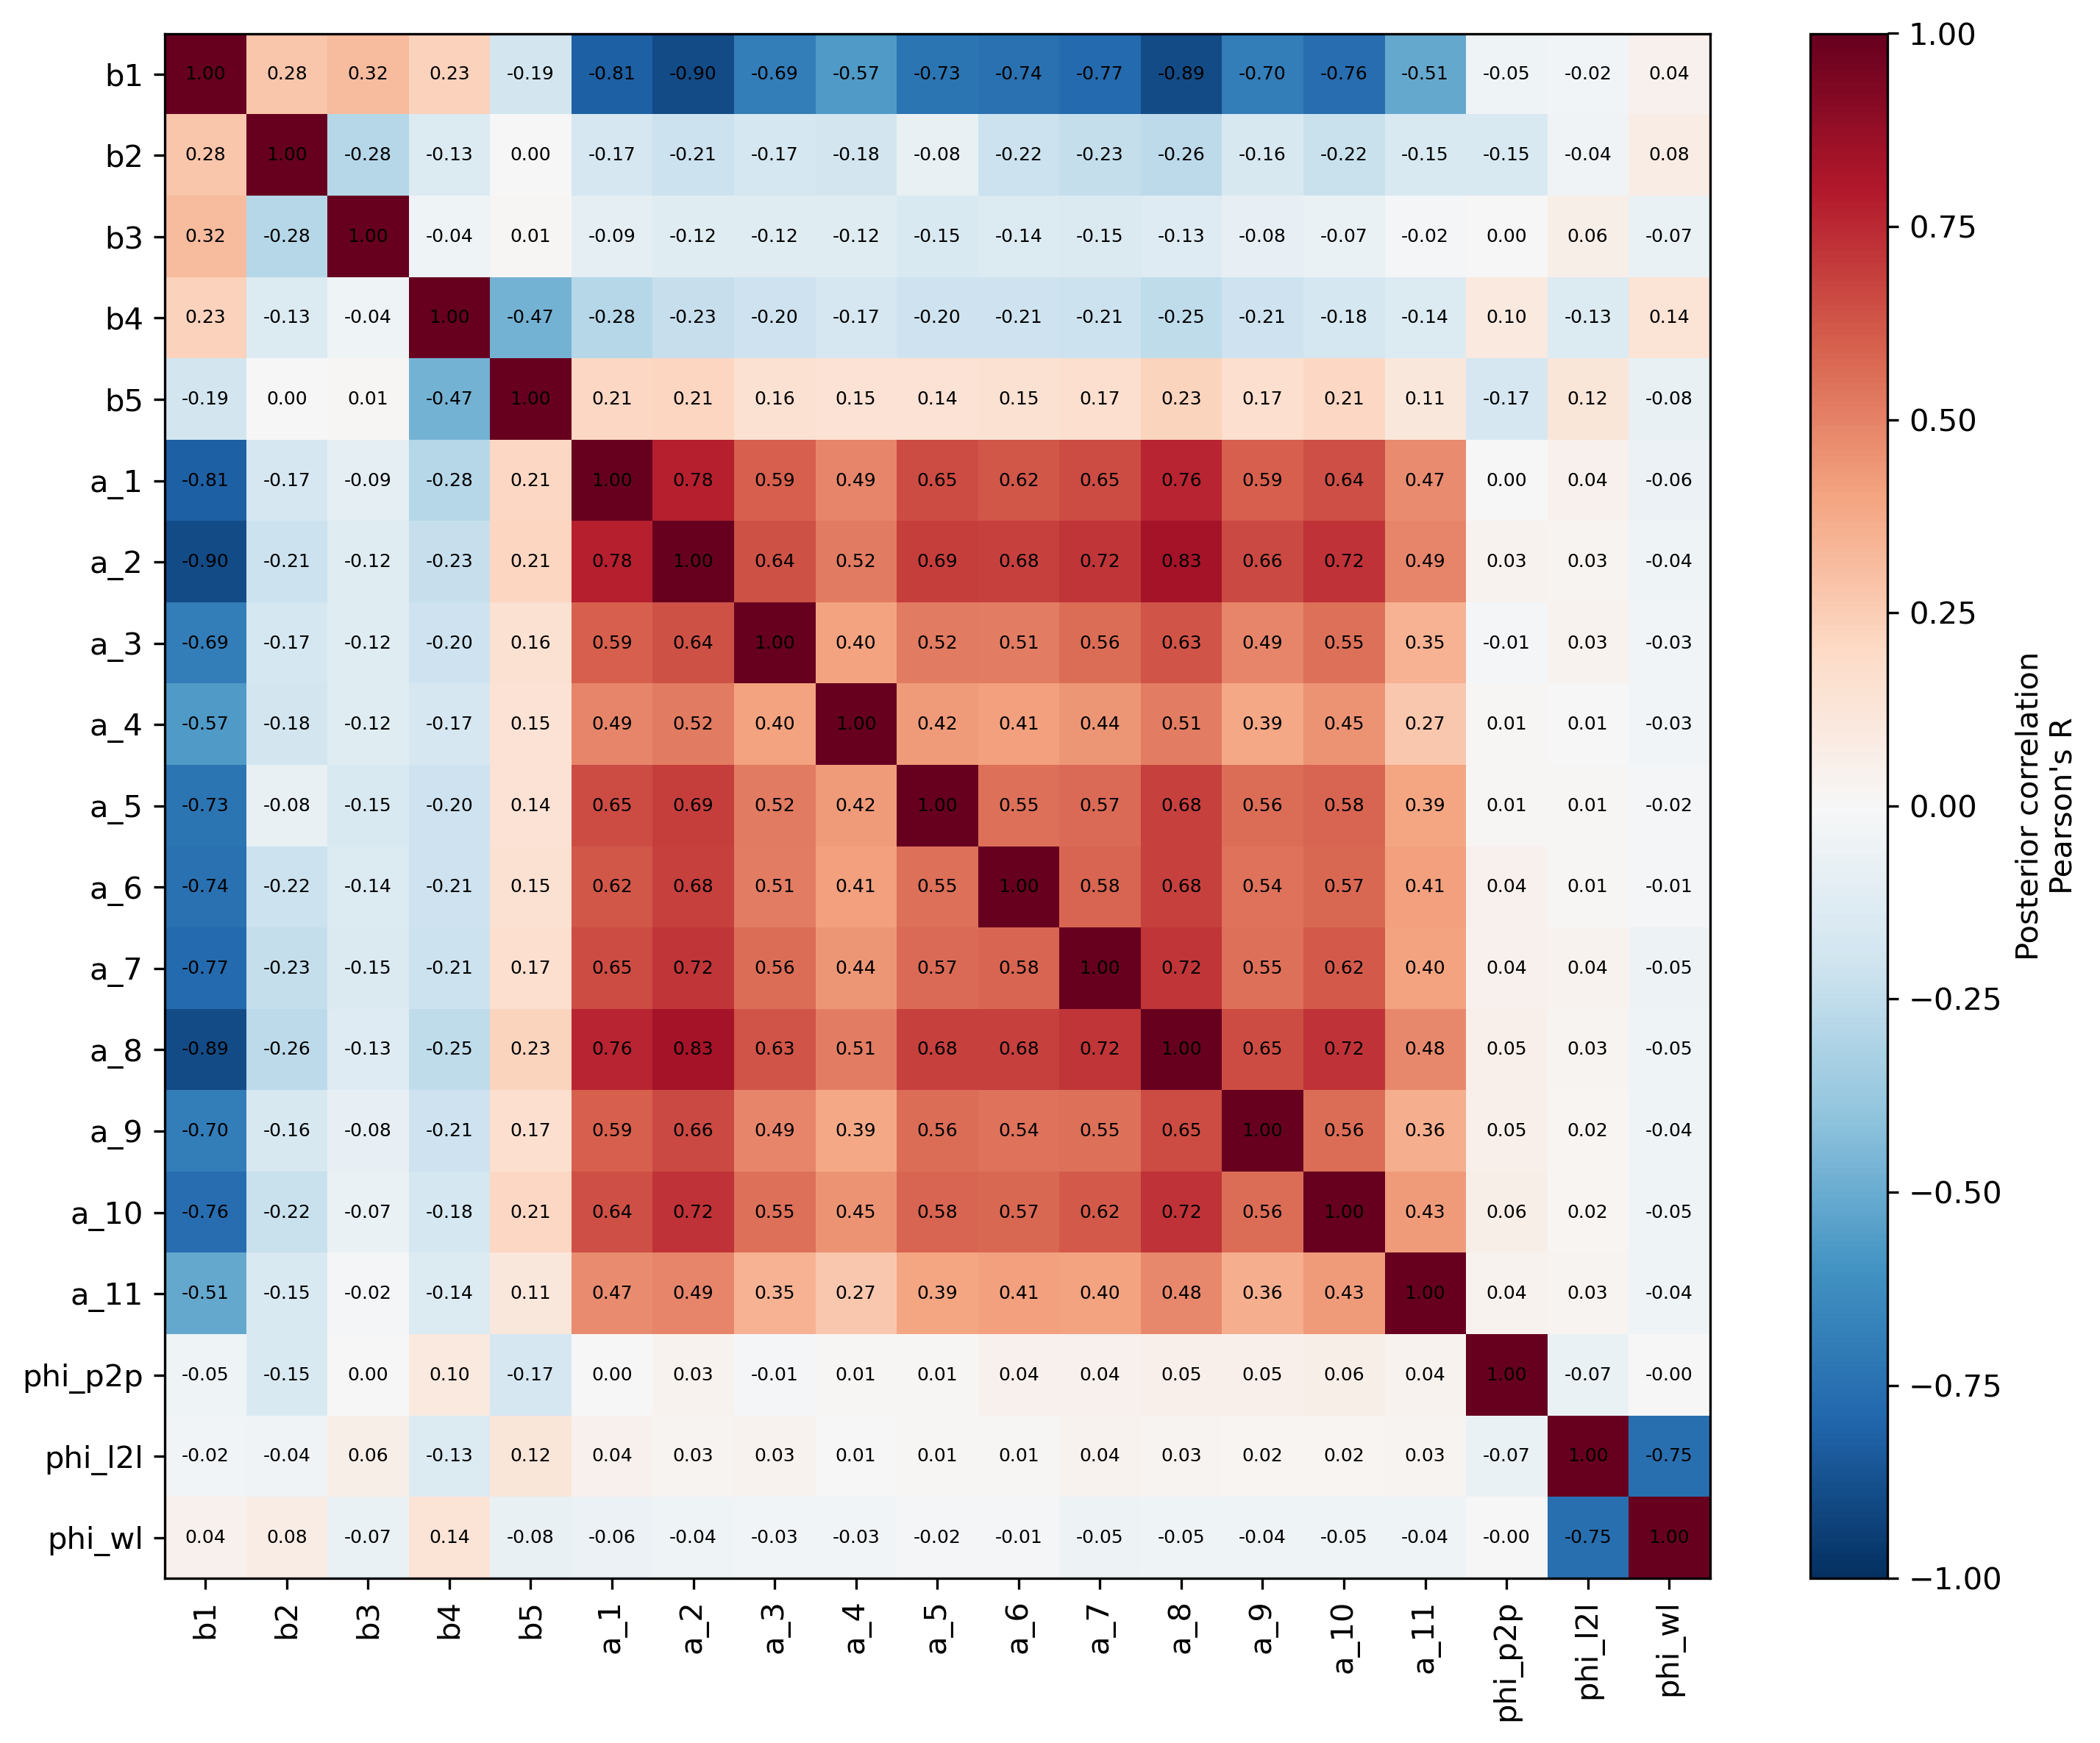

,b1,b2,b3,b4,b5,a_1,a_2,a_3,a_4,a_5,a_6,a_7,a_8,a_9,a_10,a_11,phi_p2p,phi_l2l,phi_wl
b1,1.000000,0.276609,0.319147,0.233847,-0.186621,-0.813938,-0.896063,-0.689483,-0.567274,-0.731816,-0.743850,-0.774702,-0.892900,-0.695240,-0.758106,-0.507880,-0.045791,-0.024592,0.041787
b2,0.276609,1.000000,-0.283097,-0.133945,0.000024,-0.171417,-0.213938,-0.173708,-0.183947,-0.076203,-0.218191,-0.234437,-0.259564,-0.158635,-0.219980,-0.153353,-0.154369,-0.035900,0.075452
b3,0.319147,-0.283097,1.000000,-0.040732,0.014199,-0.094428,-0.124977,-0.118174,-0.122342,-0.152954,-0.135973,-0.145136,-0.126743,-0.078821,-0.069822,-0.021408,0.001618,0.058368,-0.069609
b4,0.233847,-0.133945,-0.040732,1.000000,-0.469441,-0.283433,-0.230910,-0.203969,-0.169910,-0.204546,-0.205192,-0.212639,-0.254422,-0.210044,-0.179409,-0.138881,0.099828,-0.133407,0.138373
b5,-0.186621,0.000024,0.014199,-0.469441,1.000000,0.209697,0.213111,0.156099,0.146576,0.144993,0.149735,0.171238,0.225324,0.167454,0.209681,0.110732,-0.168186,0.118730,-0.077773
a_1,-0.813938,-0.171417,-0.094428,-0.283433,0.209697,1.000000,0.779386,0.594778,0.485415,0.651887,0.624807,0.652925,0.764064,0.594425,0.641841,0.471283,0.003219,0.042781,-0.058960
a_2,-0.896063,-0.213938,-0.124977,-0.230910,0.213111,0.779386,1.000000,0.635032,0.518934,0.694653,0.682613,0.715765,0.834380,0.661397,0.720187,0.490402,0.034406,0.026030,-0.040442
a_3,-0.689483,-0.173708,-0.118174,-0.203969,0.156099,0.594778,0.635032,1.000000,0.399386,0.523395,0.508948,0.556833,0.632306,0.485570,0.547318,0.349091,-0.009016,0.034230,-0.031172
a_4,-0.567274,-0.183947,-0.122342,-0.169910,0.146576,0.485415,0.518934,0.399386,1.000000,0.422738,0.409231,0.441563,0.513718,0.385484,0.445904,0.269768,0.013944,0.005125,-0.028332
a_5,-0.731816,-0.076203,-0.152954,-0.204546,0.144993,0.651887,0.694653,0.523395,0.422738,1.000000,0.553865,0.569534,0.682925,0.557439,0.584165,0.392115,0.014716,0.011300,-0.020107


In [21]:
post = traces5.posterior

cols = {}
for name in ["b", "a", "phi_p2p", "phi_l2l", "phi_wl"]:
    v = post[name].stack(sample=("chain", "draw")).values  # shape (..., n_samples)
    if v.ndim == 1:
        cols[name] = v
    else:
        for j in range(v.shape[0]):
            cols[f"{name}{j + 1}" if name == "b" else f"a_{unique_groups[j]}"] = v[j]

draws_df = pd.DataFrame(cols)
corr = draws_df.corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, label="Posterior correlation\nPearson's R")
plt.tight_layout()
plt.show()

corr


In [23]:
import arviz as az

# 1. How much does N_l vary? (more spread = better separation)
print(np.percentile(N_tt, [5, 25, 50, 75, 95]))

# 2. Marginal posteriors vs. the HalfNormal(1) prior
print(az.summary(traces5, var_names=["phi_l2l", "phi_wl"]))

# 3. The combination the data actually constrain: should be much tighter than either one alone
post = traces5.posterior
sd_layer = np.sqrt(post["phi_l2l"]**2 + post["phi_wl"]**2 / np.median(N_tt))
print(f"layer-level SD at median N_l: {float(sd_layer.mean()):.4f} ± {float(sd_layer.std()):.4f}")


[ 6. 37. 40. 40. 60.]
            mean       sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
phi_l2l  0.19705  0.00246     0.19      0.2     2493     2680  1.00   4.9e-05  3.3e-05
phi_wl    0.4564   0.0232     0.42     0.49     2499     2739  1.00   0.00046  0.00032
layer-level SD at median N_l: 0.2099 ± 0.0016
